In [1]:
import requests
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import re
import time

from bs4 import BeautifulSoup
from urllib.parse import urljoin

print("Data Science 500 - Book Market Analytics")
print("Libraries imported successfully!")

Data Science 500 - Book Market Analytics
Libraries imported successfully!


In [2]:
BASE_URL = "https://books.toscrape.com/"
HEADERS = {"User-Agent": "Mozilla/5.0"}

books = []
page_url = BASE_URL

while page_url:
    response = requests.get(
        page_url, headers=HEADERS, timeout=30
    )
    response.raise_for_status()

    soup = BeautifulSoup(response.text, "html.parser")

    # Extract books from the current catalogue page
    products = soup.select("article.product_pod")

    for product in products:
        title = product.h3.a["title"]

        price_text = product.select_one(
            ".price_color"
        ).get_text(strip=True)

        price = float(
            re.sub(r"[^0-9.]", "", price_text)
        )

        # Convert star rating words to numbers
        rating_word = product.select_one(
            ".star-rating"
        )["class"][-1]

        rating_map = {
            "One": 1,
            "Two": 2,
            "Three": 3,
            "Four": 4,
            "Five": 5
        }

        rating = rating_map[rating_word]

        # Open the individual book page
        book_url = urljoin(
            page_url, product.h3.a["href"]
        )

        detail_response = requests.get(
            book_url, headers=HEADERS, timeout=30
        )
        detail_response.raise_for_status()

        detail = BeautifulSoup(
            detail_response.text, "html.parser"
        )

        # Extract stock information
        availability = detail.select_one(
            ".availability"
        )

        stock_text = (
            availability.get_text(" ", strip=True)
            if availability else "Unknown"
        )

        match = re.search(
            r"\((\d+)\s+available\)", stock_text
        )

        quantity = (
            int(match.group(1)) if match else None
        )

        stock_status = (
            "In stock"
            if "in stock" in stock_text.lower()
            else "Out of stock"
            if "out of stock" in stock_text.lower()
            else "Unknown"
        )

        # Extract genre
        breadcrumb = detail.select(
            "ul.breadcrumb li a"
        )

        genre = (
            breadcrumb[-1].get_text(strip=True)
            if len(breadcrumb) >= 3
            else "Unknown"
        )

        # Extract description
        description_element = detail.select_one(
            "#product_description + p"
        )

        description = (
            description_element.get_text(strip=True)
            if description_element else ""
        )

        books.append({
            "title": title,
            "price_gbp": price,
            "rating_word": rating_word,
            "rating": rating,
            "stock_status": stock_status,
            "stock_quantity": quantity,
            "genre": genre,
            "description": description,
            "product_url": book_url
        })

        time.sleep(0.1)

    # Move to the next catalogue page
    next_link = soup.select_one("li.next a")

    if next_link:
        page_url = urljoin(
            page_url, next_link["href"]
        )
    else:
        page_url = None

    print("Books collected:", len(books))

print("Data acquisition completed!")
print("Total books collected:", len(books))

Books collected: 20
Books collected: 40
Books collected: 60
Books collected: 80
Books collected: 100
Books collected: 120
Books collected: 140
Books collected: 160
Books collected: 180
Books collected: 200
Books collected: 220
Books collected: 240
Books collected: 260
Books collected: 280
Books collected: 300
Books collected: 320
Books collected: 340
Books collected: 360
Books collected: 380
Books collected: 400
Books collected: 420
Books collected: 440
Books collected: 460
Books collected: 480
Books collected: 500
Books collected: 520
Books collected: 540
Books collected: 560
Books collected: 580
Books collected: 600
Books collected: 620
Books collected: 640
Books collected: 660
Books collected: 680
Books collected: 700
Books collected: 720
Books collected: 740
Books collected: 760
Books collected: 780
Books collected: 800
Books collected: 820
Books collected: 840
Books collected: 860
Books collected: 880
Books collected: 900
Books collected: 920
Books collected: 940
Books collected: 

In [3]:
import pandas as pd

df = pd.DataFrame(books)

df.to_csv("books_dataset.csv", index=False)

print("Dataset saved successfully!")
print("Total books:", len(df))

display(df.head())

Dataset saved successfully!
Total books: 1000


,title,price_gbp,rating_word,rating,stock_status,stock_quantity,genre,description,product_url
0,A Light in the Attic,51.77,Three,3,In stock,22,Poetry,It's hard to imagine a world without A Light i...,https://books.toscrape.com/catalogue/a-light-i...
1,Tipping the Velvet,53.74,One,1,In stock,20,Historical Fiction,"""Erotic and absorbing...Written with starling ...",https://books.toscrape.com/catalogue/tipping-t...
2,Soumission,50.10,One,1,In stock,20,Fiction,"Dans une France assez proche de la nÃ´tre, un ...",https://books.toscrape.com/catalogue/soumissio...
3,Sharp Objects,47.82,Four,4,In stock,20,Mystery,"WICKED above her hipbone, GIRL across her hear...",https://books.toscrape.com/catalogue/sharp-obj...
4,Sapiens: A Brief History of Humankind,54.23,Five,5,In stock,20,History,From a renowned historian comes a groundbreaki...,https://books.toscrape.com/catalogue/sapiens-a...


In [4]:
print("Dataset information:")
df.info()

print("\nMissing values in each column:")
print(df.isnull().sum())

print("\nDuplicate book titles:")
print(df["title"].duplicated().sum())

print("\nNumber of unique genres:")
print(df["genre"].nunique())

print("\nSummary of numerical data:")
display(df[["price_gbp", "rating", "stock_quantity"]].describe())

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 9 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   title           1000 non-null   str    
 1   price_gbp       1000 non-null   float64
 2   rating_word     1000 non-null   str    
 3   rating          1000 non-null   int64  
 4   stock_status    1000 non-null   str    
 5   stock_quantity  1000 non-null   int64  
 6   genre           1000 non-null   str    
 7   description     1000 non-null   str    
 8   product_url     1000 non-null   str    
dtypes: float64(1), int64(2), str(6)
memory usage: 70.4 KB

Missing values in each column:
title             0
price_gbp         0
rating_word       0
rating            0
stock_status      0
stock_quantity    0
genre             0
description       0
product_url       0
dtype: int64

Duplicate book titles:
1

Number of unique genres:
50

Summary of numerical data:


,price_gbp,rating,stock_quantity
count,1000.00000,1000.000000,1000.000000
mean,35.07035,2.923000,8.585000
std,14.44669,1.434967,5.654622
min,10.00000,1.000000,1.000000
25%,22.10750,2.000000,3.000000
50%,35.98000,3.000000,7.000000
75%,47.45750,4.000000,14.000000
max,59.99000,5.000000,22.000000


In [5]:
# Check missing values
print("Missing values before cleaning:")
print(df.isnull().sum())

Missing values before cleaning:
title             0
price_gbp         0
rating_word       0
rating            0
stock_status      0
stock_quantity    0
genre             0
description       0
product_url       0
dtype: int64


In [6]:
print("Rows before cleaning:", len(df))

# Remove duplicate book records
df = df.drop_duplicates(subset=["title"])

print("Rows after removing duplicates:", len(df))

# Check missing values again
print("\nMissing values remaining:")
print(df.isnull().sum())

Rows before cleaning: 1000
Rows after removing duplicates: 999

Missing values remaining:
title             0
price_gbp         0
rating_word       0
rating            0
stock_status      0
stock_quantity    0
genre             0
description       0
product_url       0
dtype: int64


In [7]:
print("Missing values in each column:")
print(df.isnull().sum())

print("\nPercentage of missing values:")
print((df.isnull().sum() / len(df) * 100).round(2))

Missing values in each column:
title             0
price_gbp         0
rating_word       0
rating            0
stock_status      0
stock_quantity    0
genre             0
description       0
product_url       0
dtype: int64

Percentage of missing values:
title             0.0
price_gbp         0.0
rating_word       0.0
rating            0.0
stock_status      0.0
stock_quantity    0.0
genre             0.0
description       0.0
product_url       0.0
dtype: float64


In [8]:
print("Data types before correction:")
print(df.dtypes)

# Convert columns to the correct data types
df["price_gbp"] = pd.to_numeric(df["price_gbp"], errors="coerce")
df["rating"] = pd.to_numeric(df["rating"], errors="coerce")
df["stock_quantity"] = pd.to_numeric(
    df["stock_quantity"], errors="coerce"
)

print("\nData types after correction:")
print(df.dtypes)

Data types before correction:
title                 str
price_gbp         float64
rating_word           str
rating              int64
stock_status          str
stock_quantity      int64
genre                 str
description           str
product_url           str
dtype: object

Data types after correction:
title                 str
price_gbp         float64
rating_word           str
rating              int64
stock_status          str
stock_quantity      int64
genre                 str
description           str
product_url           str
dtype: object


In [9]:
df.to_csv("books_dataset_cleaned.csv", index=False)

print("Cleaned dataset saved successfully!")
print("Total books:", len(df))

Cleaned dataset saved successfully!
Total books: 999


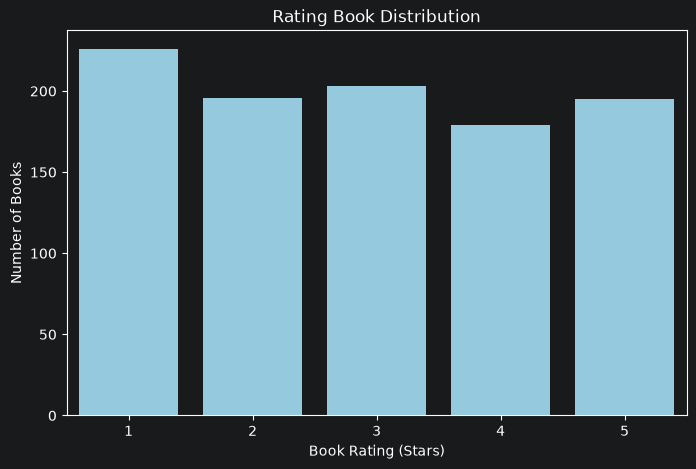

In [41]:
plt.figure(figsize=(8, 5))

sns.countplot(data=df, x="rating", color="skyblue")

plt.title("Rating Book Distribution")
plt.xlabel("Book Rating (Stars)")
plt.ylabel("Number of Books")

plt.savefig("Rating Book Distribution", dpi=300, bbox_inches="tight")
plt.show()

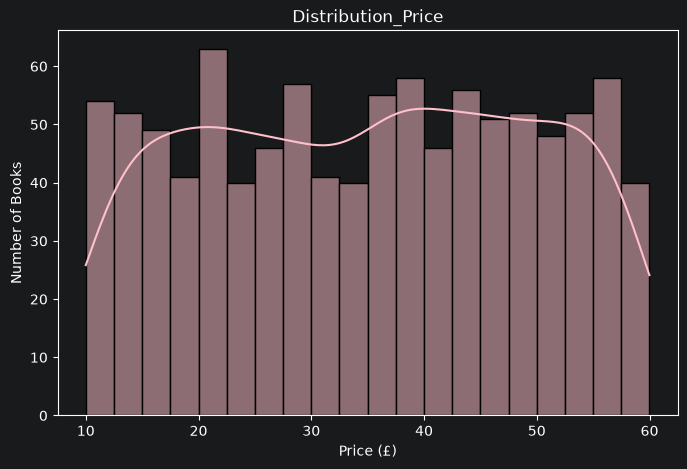

Distribution_Price.png saved successfully!


In [45]:
plt.figure(figsize=(8, 5))

sns.histplot(
    data=df,
    x="price_gbp",
    bins=20,
    kde=True,
    color="pink"
)

plt.title("Distribution_Price")
plt.xlabel("Price (£)")
plt.ylabel("Number of Books")

plt.savefig("Distribution_Price", dpi=300, bbox_inches="tight")
plt.show()

print("Distribution_Price.png saved successfully!")

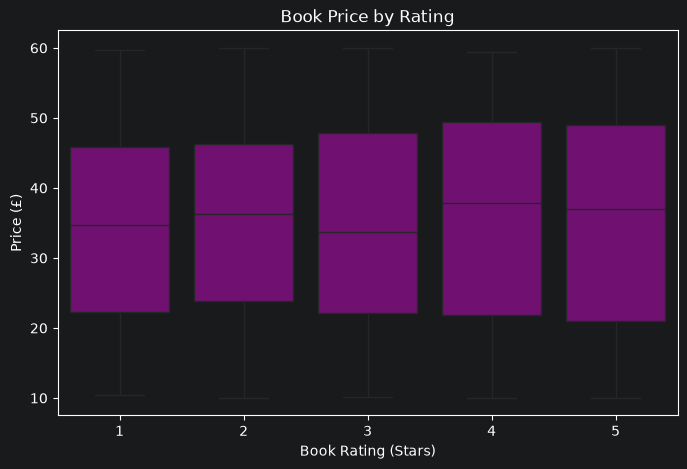

Book_Price_by_Rating saved successfully!


In [47]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x="rating",
    y="price_gbp",
    color="purple"
)

plt.title("Book Price by Rating")
plt.xlabel("Book Rating (Stars)")
plt.ylabel("Price (£)")

plt.savefig("Book_Price_by_Rating", dpi=300, bbox_inches="tight")
plt.show()

print("Book_Price_by_Rating saved successfully!")

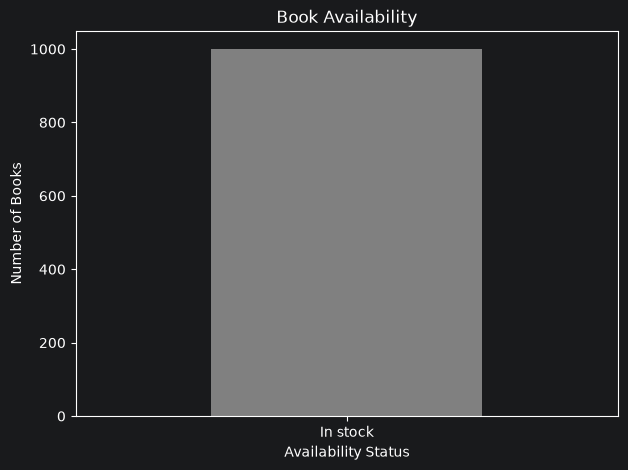

Book_Availability saved successfully!
stock_status
In stock    999
Name: count, dtype: int64


In [48]:
availability_counts = df["stock_status"].value_counts()

plt.figure(figsize=(7, 5))

availability_counts.plot(
    kind="bar",
    color=["grey", "tomato"]
)

plt.title("Book Availability")
plt.xlabel("Availability Status")
plt.ylabel("Number of Books")
plt.xticks(rotation=0)

plt.savefig("Book_Availability", dpi=300, bbox_inches="tight")
plt.show()

print("Book_Availability saved successfully!")
print(availability_counts)

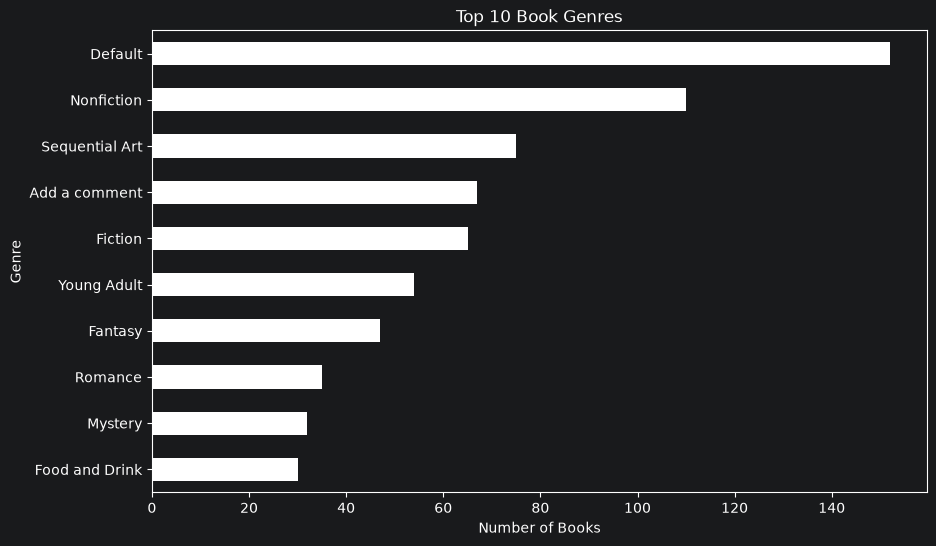

Top10_Book_Genres saved successfully!


In [49]:
genre_counts = df["genre"].value_counts().head(10)

plt.figure(figsize=(10, 6))

genre_counts.sort_values().plot(
    kind="barh",
    color="white"
)

plt.title("Top 10 Book Genres")
plt.xlabel("Number of Books")
plt.ylabel("Genre")

plt.savefig("Top10_Book_Genres", dpi=300, bbox_inches="tight")
plt.show()

print("Top10_Book_Genres saved successfully!")

In [28]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Select the input feature and target
X = df[["rating"]]
y = df["price_gbp"]

# Split the data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Data prepared successfully!")
print("Training records:", len(X_train))
print("Testing records:", len(X_test))

Data prepared successfully!
Training records: 799
Testing records: 200


In [30]:
y_pred = model.predict(X_test)

results = pd.DataFrame({
    "Actual Price (£)": y_test.values,
    "Predicted Price (£)": y_pred
})

display(results.head(10))

,Actual Price (£),Predicted Price (£)
0,35.88,34.497992
1,39.13,34.497992
2,15.48,34.882337
3,57.62,36.035373
4,55.55,34.882337
5,56.88,35.651028
6,31.58,36.035373
7,39.67,34.882337
8,33.95,35.651028
9,50.44,35.651028


In [31]:
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print("Mean Absolute Error (MAE):", round(mae, 2))
print("Root Mean Squared Error (RMSE):", round(rmse, 2))
print("R-squared (R2):", round(r2, 4))

Mean Absolute Error (MAE): 12.23
Root Mean Squared Error (RMSE): 14.17
R-squared (R2): -0.0053


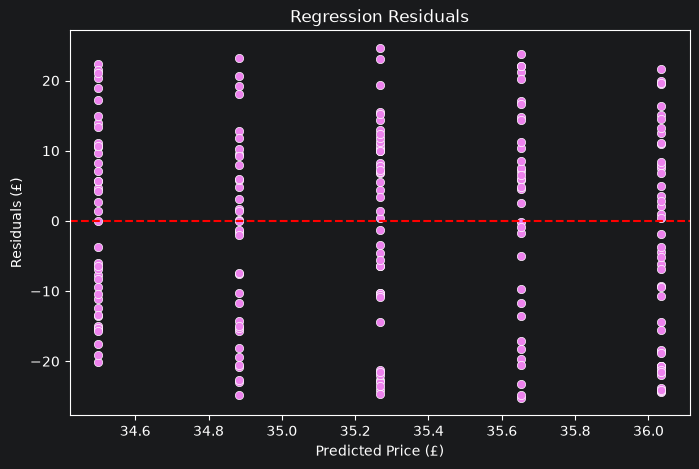

Regression residuals graph saved successfully!


In [32]:
residuals = y_test - y_pred

plt.figure(figsize=(8, 5))

sns.scatterplot(x=y_pred, y=residuals, color="Violet")

plt.axhline(y=0, color="red", linestyle="--")

plt.title("Regression Residuals")
plt.xlabel("Predicted Price (£)")
plt.ylabel("Residuals (£)")

plt.savefig(
    "regression_residuals.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Regression residuals graph saved successfully!")

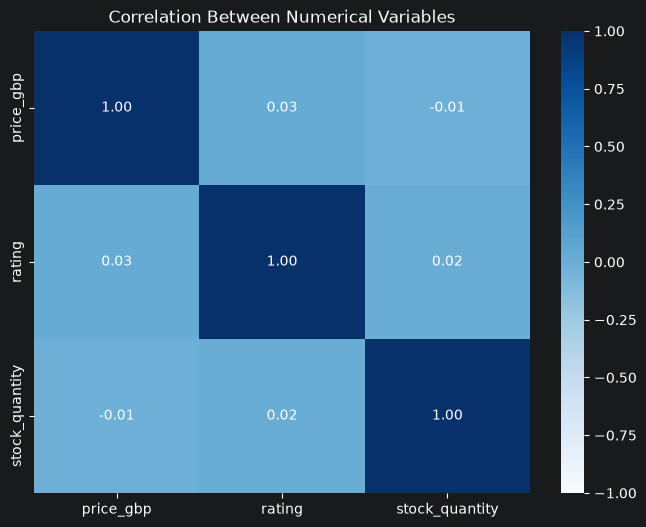

Correlation graph saved successfully!


In [39]:
numerical_data = df[
    ["price_gbp", "rating", "stock_quantity"]
].dropna()

correlation_matrix = numerical_data.corr()

plt.figure(figsize=(8, 6))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="Blues",
    fmt=".2f",
    vmin=-1,
    vmax=1
)

plt.title("Correlation Between Numerical Variables")

plt.savefig(
    "correlation.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Correlation graph saved successfully!")

In [40]:
df.to_csv("books_dataset_cleaned.csv", index=False)

print("Final cleaned dataset saved successfully!")
print("Total books:", len(df))

Final cleaned dataset saved successfully!
Total books: 999
